# 01 - Exploratory Data Analysis

**Data source:** [Spotify Tracks Dataset](https://raw.githubusercontent.com/Juanfra21/Data-Science/main/Final-Project/spotify_dataset.csv)
(114,000 real tracks pulled from the Spotify Web API, mirrored publicly on GitHub).

Each row is one track with metadata (name, artist, album), a popularity score,
and Spotify's own audio-feature analysis (danceability, energy, valence, etc.)
plus a genre label. This notebook explores the raw data before we build any
recommender components.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option('display.max_columns', 30)

df = pd.read_csv('../data/raw/spotify_tracks_dataset.csv').drop(columns=['Unnamed: 0'])
print(df.shape)
df.head()

(114000, 20)


,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,1,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,1,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,0,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,0,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,2,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


## Basic structure and data quality

In [2]:
print(df.dtypes)
print()
print("Missing values per column:")
print(df.isnull().sum()[df.isnull().sum() > 0])
print()
print("Duplicate (track_name, artists) pairs:", df.duplicated(subset=['track_name', 'artists']).sum())

track_id                str
artists                 str
album_name              str
track_name              str
popularity            int64
duration_ms           int64
explicit               bool
danceability        float64
energy              float64
key                   int64
loudness            float64
mode                  int64
speechiness         float64
acousticness        float64
instrumentalness    float64
liveness            float64
valence             float64
tempo               float64
time_signature        int64
track_genre             str
dtype: object

Missing values per column:
artists       1
album_name    1
track_name    1
dtype: int64

Duplicate (track_name, artists) pairs: 32656


In [3]:
df = df.dropna(subset=['track_name', 'artists', 'album_name']).reset_index(drop=True)
print("Shape after dropping the handful of null text fields:", df.shape)

Shape after dropping the handful of null text fields: (113999, 20)


## How many genres, and how are tracks distributed across them?

In [4]:
print("Unique genres:", df['track_genre'].nunique())
genre_counts = df['track_genre'].value_counts()
genre_counts.head(15)

Unique genres: 114


track_genre
acoustic         1000
afrobeat         1000
alt-rock         1000
alternative      1000
ambient          1000
anime            1000
black-metal      1000
bluegrass        1000
blues            1000
brazil           1000
breakbeat        1000
british          1000
cantopop         1000
chicago-house    1000
children         1000
Name: count, dtype: int64

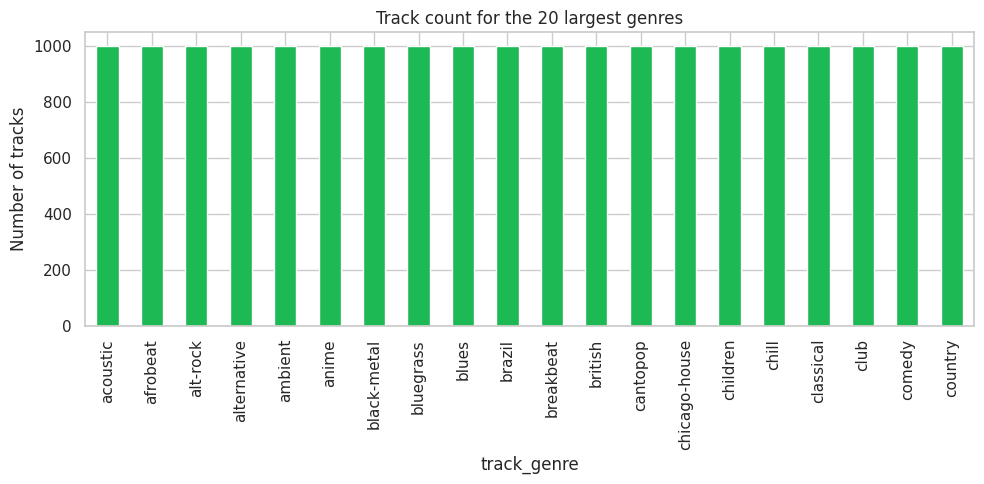

In [5]:
fig, ax = plt.subplots(figsize=(10, 5))
genre_counts.head(20).plot(kind='bar', ax=ax, color='#1DB954')
ax.set_title('Track count for the 20 largest genres')
ax.set_ylabel('Number of tracks')
plt.tight_layout()
plt.savefig('genre_counts.png', dpi=100)
plt.show()

## Popularity distribution

Most tracks in any large catalog are not hits - popularity is heavily right-skewed toward 0.

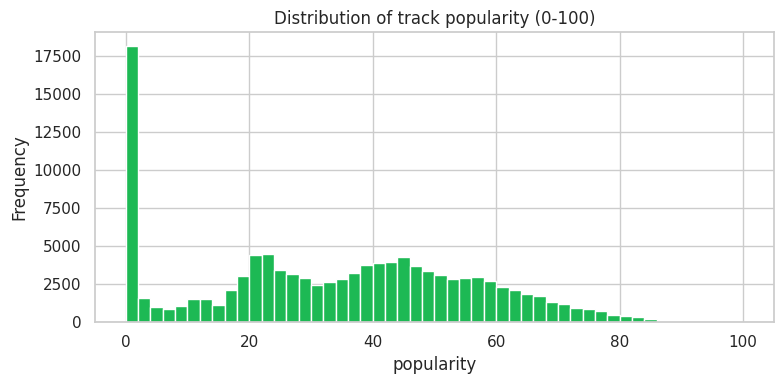

count    113999.000000
mean         33.238827
std          22.304959
min           0.000000
25%          17.000000
50%          35.000000
75%          50.000000
max         100.000000
Name: popularity, dtype: float64

In [6]:
fig, ax = plt.subplots(figsize=(8, 4))
df['popularity'].plot(kind='hist', bins=50, ax=ax, color='#1DB954')
ax.set_title('Distribution of track popularity (0-100)')
ax.set_xlabel('popularity')
plt.tight_layout()
plt.savefig('popularity_hist.png', dpi=100)
plt.show()
df['popularity'].describe()

## Audio feature correlations

These are the numeric audio features Spotify computes per track. Understanding
how they relate to each other matters later when we build content embeddings -
highly correlated features add redundancy rather than new signal.

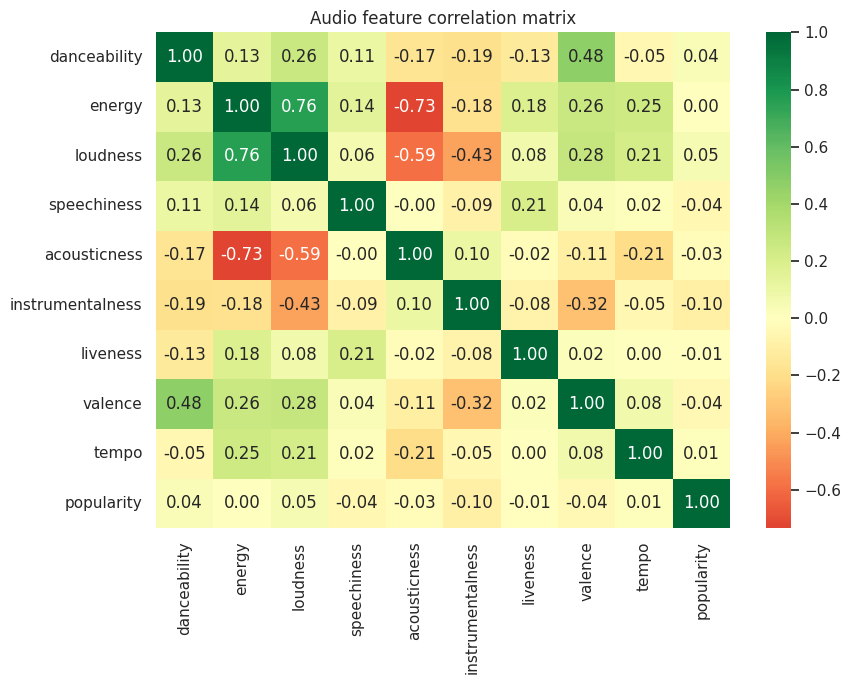

In [7]:
audio_features = ['danceability', 'energy', 'loudness', 'speechiness',
                   'acousticness', 'instrumentalness', 'liveness', 'valence',
                   'tempo', 'popularity']

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(df[audio_features].corr(), annot=True, fmt='.2f', cmap='RdYlGn', center=0, ax=ax)
ax.set_title('Audio feature correlation matrix')
plt.tight_layout()
plt.savefig('feature_correlations.png', dpi=100)
plt.show()

**Takeaways:**

- `energy` and `loudness` are strongly correlated (as expected - louder
  masters tend to read as more energetic).
- `acousticness` is strongly *negatively* correlated with `energy`, which
  matches intuition: acoustic tracks tend to be lower-energy.
- `popularity` doesn't correlate strongly with any single audio feature,
  meaning we can't just heuristically guess popularity from the numbers -
  a real model (or, in a recommender, real interaction data) is needed.

## Artist concentration

Are a small number of artists responsible for a large share of the catalog?

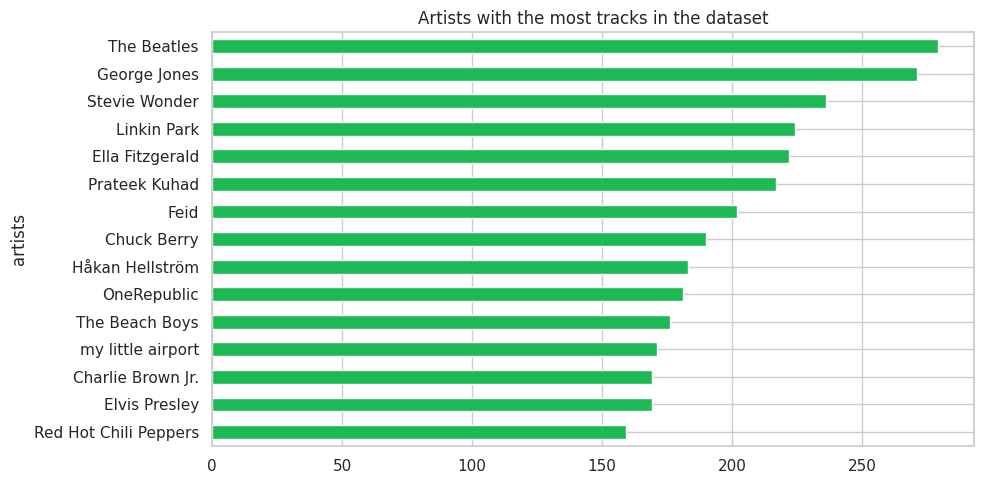

In [8]:
top_artists = df['artists'].value_counts().head(15)
fig, ax = plt.subplots(figsize=(10, 5))
top_artists.plot(kind='barh', ax=ax, color='#1DB954')
ax.invert_yaxis()
ax.set_title('Artists with the most tracks in the dataset')
plt.tight_layout()
plt.savefig('top_artists.png', dpi=100)
plt.show()

## Summary

- The catalog is broad (114 genres) and mostly low-popularity, which is
  realistic for a music platform - a handful of hits, a long tail of
  everything else.
- Audio features are internally consistent (energy/loudness/acousticness
  relationships match musical intuition), so they're usable as content
  features later.
- There's no `playlist_id` or user-interaction column in this dataset - it's
  a track catalog, not playlist logs (real Spotify playlist logs are only
  available through the restricted-access Million Playlist Dataset). The
  next notebook builds a documented, genre-based playlist structure on top
  of this real catalog so the rest of the pipeline has something concrete
  to train the collaborative-filtering model against.